# Etapa 4 — Regressão logística (H1)

Projeto SME0828 — Introdução à Ciência de Dados, ICMC/USP.

Semente do código: 444. Reexecute o notebook para atualizar os resultados exibidos.


A taxa bruta de negação é maior entre mulheres, mas os grupos podem ter perfis diferentes. Usamos regressão logística com controles de renda, DTI, LTV e tipo de empréstimo para estimar a associação ajustada.

H1: o gênero está associado à probabilidade de negação após esses controles. Testamos se o coeficiente de `mulher` difere de zero, com nível de significância de 5%.

### Odds ratio e efeito em pontos percentuais

A regressão logística modela o logaritmo das chances de negação:

$$\ln\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1\,\text{mulher} + \beta_2\,\text{log(renda)} + \dots$$

A odds ratio do gênero é $e^{\beta_1}$. OR = 1 indica chances iguais; OR > 1 indica chances maiores para mulheres; OR < 1 indica chances menores.

Também reportamos o efeito em pontos percentuais (p.p.), que expressa a mudança estimada na probabilidade de negação.

### Bibliotecas

Usamos `pyfixest` para estimar os modelos com efeitos fixos de instituição e estado em uma base grande.

In [11]:
from pathlib import Path
import os
import sys

ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Abra este notebook dentro do repositório, que deve conter a pasta data/")
os.chdir(ROOT)

SCRIPTS = ROOT / "code" / "scripts"
if str(SCRIPTS) not in sys.path:
    sys.path.insert(0, str(SCRIPTS))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from regressao_logistica_h1 import (
    AMOSTRA_TESTE,
    ARQUIVO_DADOS,
    DTI_NIVEIS,
    IDADE_NIVEIS,
    PASTA_SAIDA,
    TIPO_NIVEIS,
    criar_especificacoes,
    estimar_especificacoes,
    formula_especificacao,
    preparar_dados,
    salvar_resultados,
)

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GRAY = "#898781"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
(ROOT / "figuras").mkdir(parents=True, exist_ok=True)

### 2. Leitura e preparação dos dados

A amostra principal passa pelos filtros do protocolo: renda positiva, LTV winsorizado e, nas especificações principais, estado e idade informados. As análises S1 e S2 relaxam parte desses filtros.

In [12]:
todas, base, principal, controles, nomes_idade, fluxo_df, rotulos = preparar_dados(
    ARQUIVO_DADOS, AMOSTRA_TESTE
)
print("Fluxo da amostra:")
fluxo_df

Fluxo da amostra:


,etapa,removidas,negacoes_removidas,taxa_negacao_removidas,pct_mulher_removidas,n_restante
0,Amostra principal (entrada),0,0,NaN,NaN,1547246
1,Renda <= 0 (log indefinido),7111,4627,0.650682,0.374490,1540135
2,"LTV winsorizado em [13.99, 115.52] (nenhuma li...",0,0,NaN,NaN,1540135
3,state_code faltante,7167,6925,0.966234,0.508023,1532968
4,applicant_age faltante,83,67,0.807229,0.421687,1532885


### 3. Variáveis categóricas

DTI, tipo de empréstimo e idade são categóricos. Criamos variáveis indicadoras com `pd.get_dummies(..., drop_first=True)` e usamos a primeira categoria como referência: DTI `<20%`, empréstimo convencional e idade `25-34`.

In [13]:
pd.DataFrame({
    "Variável": ["DTI", "Tipo de empréstimo", "Faixa etária"],
    "Categoria de referência": [DTI_NIVEIS[0], TIPO_NIVEIS[0], IDADE_NIVEIS[0]],
})

,Variável,Categoria de referência
0,DTI,<20%
1,Tipo de empréstimo,1
2,Faixa etária,25-34


### 4. Especificações

Adicionamos controles em etapas para observar como a estimativa muda. A especificação principal inclui renda, LTV, DTI, tipo de empréstimo e efeitos fixos de instituição e estado. A análise E1 também controla por idade.

Um efeito fixo equivale a controlar por cada estado ou instituição. Os erros-padrão são agrupados por instituição para considerar que pedidos do mesmo banco seguem regras semelhantes.

No `pyfixest`, os efeitos fixos aparecem depois da barra `|`.

In [14]:
especificacoes = criar_especificacoes(
    todas, base, principal, controles, nomes_idade
)
pd.DataFrame({
    "Especificação": [spec["nome"] for spec in especificacoes],
    "Fórmula": [formula_especificacao(spec) for spec in especificacoes],
})

,Especificação,Fórmula
0,(1) Só gênero,negado ~ mulher
1,(2) + controles,negado ~ mulher + log_income + ltv + dti_1 + d...
2,(3) + EF estado,negado ~ mulher + log_income + ltv + dti_1 + d...
3,(4) + EF instituição,negado ~ mulher + log_income + ltv + dti_1 + d...
4,(5) + EF instituição e estado [H1],negado ~ mulher + log_income + ltv + dti_1 + d...
5,S1: (4) sem exigir state_code/idade,negado ~ mulher + log_income + ltv + dti_1 + d...
6,S2: (5) todas as linhas,negado ~ mulher + log_income + ltv + dti_1 + d...
7,E1: (5) + faixa etária,negado ~ mulher + log_income + ltv + dti_1 + d...


### 5. Ajuste dos modelos

O pipeline compartilhado ajusta uma regressão logística (`pf.feglm`) e um modelo linear de probabilidade (`pf.feols`) para cada especificação. A logística fornece a odds ratio; o modelo linear serve como verificação do efeito em pontos percentuais. As especificações com efeitos fixos levam alguns minutos.

In [15]:
res_df, coefs_df = estimar_especificacoes(especificacoes, rotulos)
tabela = res_df.rename(columns={
    "especificacao": "Especificação",
    "n_obs": "N",
    "odds_ratio": "OR",
    "or_ic95_inf": "OR IC inf",
    "or_ic95_sup": "OR IC sup",
    "p_valor": "p-valor",
    "mpl_pp": "Efeito (p.p.)",
    "mpl_ic95_inf_pp": "p.p. IC inf",
    "mpl_ic95_sup_pp": "p.p. IC sup",
})[[
    "Especificação", "N", "OR", "OR IC inf", "OR IC sup",
    "p-valor", "Efeito (p.p.)", "p.p. IC inf", "p.p. IC sup",
]]
tabela.round(3)


Estimando (1) Só gênero
  N = 1,532,885 | OR = 1.160 | AME = 1.41 p.p. (2.2s)

Estimando (2) + controles
  N = 1,532,885 | OR = 1.022 | AME = 0.16 p.p. (5.4s)

Estimando (3) + EF estado
  N = 1,532,885 | OR = 1.010 | AME = 0.07 p.p. (6.6s)

Estimando (4) + EF instituição
  N = 1,514,115 | OR = 1.015 | AME = 0.09 p.p. (9.6s)

Estimando (5) + EF instituição e estado [H1]
  N = 1,514,115 | OR = 1.005 | AME = 0.04 p.p. (21.1s)

Estimando S1: (4) sem exigir state_code/idade
  N = 1,521,774 | OR = 1.017 | AME = 0.11 p.p. (9.8s)

Estimando S2: (5) todas as linhas
  N = 1,529,269 | OR = 1.006 | AME = 0.04 p.p. (29.4s)

Estimando E1: (5) + faixa etária
  N = 1,514,115 | OR = 0.974 | AME = -0.17 p.p. (34.7s)


,Especificação,N,OR,OR IC inf,OR IC sup,p-valor,Efeito (p.p.),p.p. IC inf,p.p. IC sup
0,(1) Só gênero,1532885,1.160,1.098,1.225,0.000,1.409,0.777,2.041
1,(2) + controles,1532885,1.022,0.988,1.057,0.205,0.197,-0.075,0.468
2,(3) + EF estado,1532885,1.010,0.976,1.045,0.561,0.123,-0.153,0.399
3,(4) + EF instituição,1514115,1.015,0.989,1.041,0.264,0.080,-0.099,0.260
4,(5) + EF instituição e estado [H1],1514115,1.005,0.980,1.032,0.678,0.026,-0.154,0.206
5,S1: (4) sem exigir state_code/idade,1521774,1.017,0.992,1.044,0.184,0.090,-0.093,0.272
6,S2: (5) todas as linhas,1529269,1.006,0.981,1.032,0.658,0.012,-0.170,0.194
7,E1: (5) + faixa etária,1514115,0.974,0.948,1.000,0.050,-0.203,-0.393,-0.013


### 6. Resultados

O gráfico mostra as odds ratios e os intervalos de confiança de 95%. A linha em OR = 1 indica chances iguais. Se o intervalo inclui 1, a estimativa não é estatisticamente significativa.

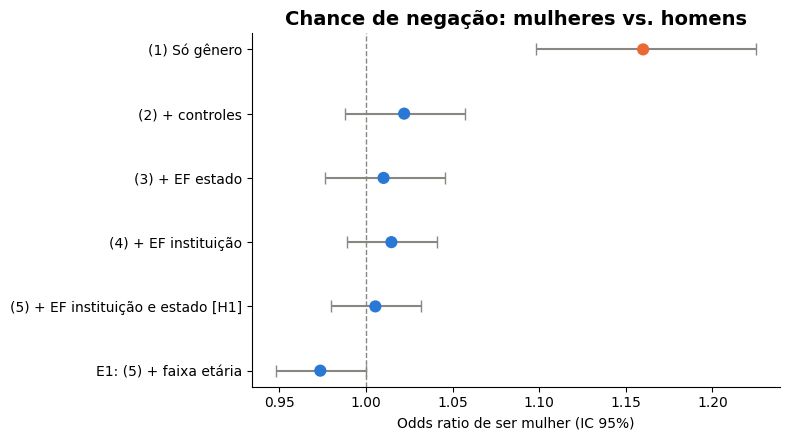

In [16]:
tabela_grafico = tabela[~tabela["Especificação"].str.startswith(("S1:", "S2:"))]
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(tabela_grafico))[::-1]
cores = [ORANGE if p < 0.05 else BLUE for p in tabela_grafico["p-valor"]]

ax.errorbar(
    tabela_grafico["OR"], y,
    xerr=[
        tabela_grafico["OR"] - tabela_grafico["OR IC inf"],
        tabela_grafico["OR IC sup"] - tabela_grafico["OR"],
    ],
    fmt="none", ecolor=GRAY, capsize=4,
)
ax.scatter(tabela_grafico["OR"], y, color=cores, s=60, zorder=3)
ax.axvline(1, color=GRAY, linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(tabela_grafico["Especificação"])
ax.set_xlabel("Odds ratio de ser mulher (IC 95%)")
ax.set_title("Chance de negação: mulheres vs. homens", fontsize=14, fontweight="bold")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/etapa_04_h1_odds_ratio.png", dpi=300)
plt.show()

Também examinamos os coeficientes dos controles na especificação principal para verificar a direção das associações estimadas.

In [17]:
nome_h1 = "(5) + EF instituição e estado [H1]"
coeficientes = (
    coefs_df.loc[coefs_df["especificacao"] == nome_h1]
    .set_index("termo")[["coef", "odds_ratio", "p_valor"]]
    .rename(columns={"coef": "coeficiente", "odds_ratio": "odds_ratio", "p_valor": "p-valor"})
)
coeficientes.round(3)

,coeficiente,odds_ratio,p-valor
termo,,,
mulher,0.005,1.005,0.678
log(renda),-0.419,0.657,0.000
LTV combinado (%),0.017,1.017,0.000
dti = 20%-<30% (ref.: <20%),-0.677,0.508,0.000
dti = 30%-<36% (ref.: <20%),-0.795,0.451,0.000
dti = 36%-<50% (ref.: <20%),-0.741,0.477,0.000
dti = 50%-60% (ref.: <20%),0.569,1.766,0.000
dti = >60% (ref.: <20%),3.875,48.169,0.000
loan_type = 2 (ref.: 1),-0.152,0.859,0.052


### 7. Salvamento dos resultados

In [18]:
salvar_resultados(
    res_df, coefs_df, fluxo_df, ARQUIVO_DADOS, AMOSTRA_TESTE, PASTA_SAIDA
)

print("Resultados da H1 salvos em resultados/.")
tabela_md = tabela.copy()
tabela_md["OR (IC 95%)"] = tabela.apply(
    lambda r: f"{r['OR']:.3f} ({r['OR IC inf']:.3f}; {r['OR IC sup']:.3f})", axis=1
)
tabela_md["Efeito em p.p. (IC 95%)"] = tabela.apply(
    lambda r: f"{r['Efeito (p.p.)']:.2f} ({r['p.p. IC inf']:.2f}; {r['p.p. IC sup']:.2f})", axis=1
)
tabela_md["p-valor"] = tabela["p-valor"].map(
    lambda p: "<0,001" if p < 0.001 else f"{p:.3f}"
)
tabela_md[["Especificação", "N", "OR (IC 95%)", "p-valor", "Efeito em p.p. (IC 95%)"]]

Resultados da H1 salvos em resultados/.


,Especificação,N,OR (IC 95%),p-valor,Efeito em p.p. (IC 95%)
0,(1) Só gênero,1532885,1.160 (1.098; 1.225),"<0,001",1.41 (0.78; 2.04)
1,(2) + controles,1532885,1.022 (0.988; 1.057),0.205,0.20 (-0.07; 0.47)
2,(3) + EF estado,1532885,1.010 (0.976; 1.045),0.561,0.12 (-0.15; 0.40)
3,(4) + EF instituição,1514115,1.015 (0.989; 1.041),0.264,0.08 (-0.10; 0.26)
4,(5) + EF instituição e estado [H1],1514115,1.005 (0.980; 1.032),0.678,0.03 (-0.15; 0.21)
5,S1: (4) sem exigir state_code/idade,1521774,1.017 (0.992; 1.044),0.184,0.09 (-0.09; 0.27)
6,S2: (5) todas as linhas,1529269,1.006 (0.981; 1.032),0.658,0.01 (-0.17; 0.19)
7,E1: (5) + faixa etária,1514115,0.974 (0.948; 1.000),0.050,-0.20 (-0.39; -0.01)


### Conclusão

- Sem controles, a OR é 1,16 (p < 0,001), equivalente a 1,4 p.p. a mais de negações para mulheres.
- Com renda, LTV, DTI e tipo de empréstimo, a OR cai para 1,02 e não é significativa (p = 0,21).
- Na especificação principal, a OR é 1,005 (IC 95%: 0,980 a 1,032; p = 0,68), com efeito estimado de 0,03 p.p.
- Não encontramos associação estatisticamente significativa entre gênero e negação após os controles disponíveis.
- Na análise exploratória com idade, a OR é 0,974 (p = 0,050), resultado limítrofe e na direção oposta.

O HMDA público não inclui credit score nem histórico de crédito. Esses fatores podem alterar a associação observada; os resultados não demonstram causalidade.